# lambdas: Parameterising REE Profiles in Mantle Xenoliths

Orthogonal polynomial decomposition can be used for dimensional reduction of smooth
function over an independent variable, producing an array of independent values
representing the relative weights for each order of component polynomial. This is an
effective method to parameterise and compare the nature of smooth profiles.

The Rare Earth Element (REE) are a collection of elements with broadly similar physicochemical
properties (the lanthanides), which vary with ionic radii. Given their similar behaviour
and typically smooth function of normalised abundance vs. ionic radii, the REE profiles
and their shapes can be effectively parameterised and dimensionally reduced (14 elements
summarised by 3-4 shape parameters):

$$
\ln([\mathrm{REE}_i]_N)
= \lambda_0
+ \lambda_1 f_1(r_i)
+ \lambda_2 f_2(r_i)
+ \lambda_3 f_3(r_i)
+ \lambda_4 f_4(r_i)
$$

where $[\mathrm{REE}_i]_N$ is the chondrite-normalised abundance of element $i$, $r_i$ is its ionic radius, and $f_n(r_i)$ are predefined orthogonal polynomials (O’Neill 2016; Anenburg 2020, 2022).

Each coefficient represents a different aspect of the REE pattern:  
- **$\lambda_0$**: total enrichment  
- **$\lambda_1$**: slope from light to heavy REE  
- **$\lambda_2$**: curvature  
- **$\lambda_3$**, **$\lambda_4$**: higher-order, fine-scale variations  


Here reduce these REE patterns to lambda values, and visualise the
results.


In [49]:
import pyrolite
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyrolite.plot

In [73]:
df = pd.read_excel('../MES - Anastasia/Sudholz_2023.xlsx')  # Kimberley
# df = pd.read_excel('../MES - Anastasia/Sudholz_2022.xlsx')  # Gawler

ree_columns = ['La','Ce','Pr','Nd','Sm','Eu','Gd','Tb','Dy','Ho','Er','Tm','Yb','Lu']

# Fix the sample column name in df (so it carries through)
df = df.rename(columns={'SAMPLE NO. ': 'SAMPLE NO.'})

# Subset ONCE, including sample numbers
df_cpx_ree = df[['SAMPLE NO.'] + ree_columns].copy()

# Clean REEs
for col in ree_columns:
    df_cpx_ree[col] = df_cpx_ree[col].replace('Below LOD', np.nan) #Replaces below detection limit to nan 
    df_cpx_ree[col] = pd.to_numeric(df_cpx_ree[col], errors='coerce') 

# Drop rows with no REE values at all
df_cpx_ree = df_cpx_ree.dropna(how='all', subset=ree_columns)

print(df_cpx_ree.shape)
df_cpx_ree.head()

(580, 15)


C:\Users\anast\AppData\Local\Temp\ipykernel_47008\2369083551.py:14: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_cpx_ree[col] = df_cpx_ree[col].replace('Below LOD', np.nan)


,SAMPLE NO.,La,Ce,Pr,Nd,Sm,Eu,Gd,Tb,Dy,Ho,Er,Tm,Yb,Lu
420,MT.L C5R5 R,6.73,23.39,3.79,17.04,2.77,0.756,1.87,0.185,0.890,0.118,0.236,0.0250,0.111,0.0139
421,MT.L C5R5 C,6.73,23.80,3.75,17.33,2.90,0.755,1.79,0.176,0.903,0.114,0.224,0.0312,0.099,0.0149
422,MT.L C8R1 R,6.21,21.04,3.41,16.22,3.01,0.862,2.06,0.203,1.090,0.131,0.280,0.0222,0.131,0.0170
423,MT.L C3R2 C,25.27,85.90,10.96,40.03,3.63,0.700,1.41,0.124,0.485,0.071,0.139,0.0150,0.078,0.0121
424,MT.L C3R3 C,12.08,36.70,5.04,19.31,2.13,0.429,0.91,0.084,0.373,0.051,0.123,0.0078,NaN,NaN


In [74]:
REE = ["La","Ce","Pr","Nd","Sm","Eu","Gd","Tb","Dy","Ho","Er","Tm","Yb","Lu"]
IONIC_RADII = np.array([1.160, 1.143, 1.126, 1.109, 1.079, 1.066,
                        1.053, 1.040, 1.027, 1.015, 1.004, 0.994,
                        0.985, 0.977])
CI = np.array([0.2472, 0.6308, 0.0950, 0.4793, 0.1542, 0.0592,
               0.2059, 0.0375, 0.2540, 0.0554, 0.1645, 0.0258,
               0.1684, 0.0251])

#This is in case we want to exclude Eu later on - Eu can be anomalous because of its two oxidation states (Eu2+ and Eu3+). 
# FYI Ce is also occasionally anomalous because of its two oxidation states, Ce3+ and Ce4+ - replace the "Eu" woth "Ce" if we want to exclude
# FYI Pm does not occur naturally, so we can also exclude
def get_mask(exclude=("Eu",), ree_order=REE):
    mask = np.ones(len(ree_order), dtype=bool)
    for el in exclude:
        if el in ree_order:
            mask[ree_order.index(el)] = False
    return mask

Lambdas (λ0..λ4): [ 1.03911930e+00 -1.63662933e-01 -1.70057426e+00  2.47625646e+01
 -3.65062617e+02]
Misfit: 1.5663109419631835


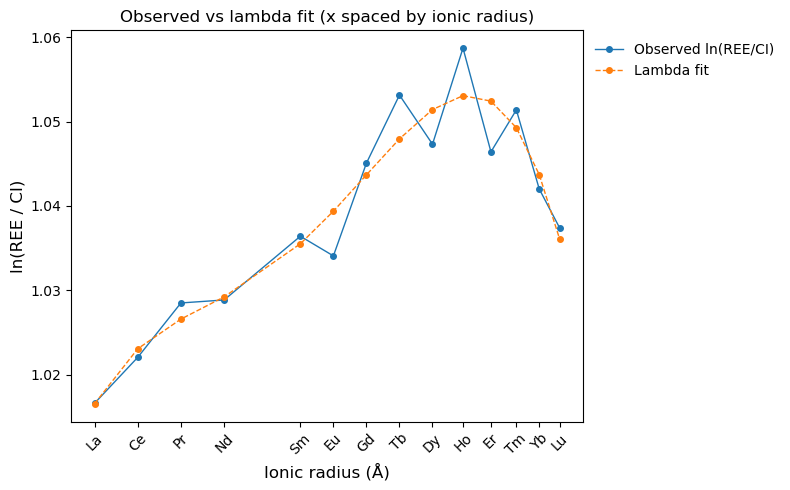

In [96]:
"""
LAMBDA FITTING FOR REE PATTERNS (O'Neill numbers)

Goal:
-----
Turn a REE pattern into lambdas λ0, λ1, λ2, λ3, λ4

Why this is useful:
-------------------
REE patterns are usually smooth curves. Instead of comparing 14 REE values,
we can compare just 3–5 numbers that describe:
- overall enrichment (λ0)
- slope (λ1)
- curvature (λ2)
- end inflections (λ3)
- W-shape / higher detail (λ4)

The model predicts the LOG of CI-normalised REE values using a combination of shape curves based on ionic radius.

We fit:
ln(REE/CI) ≈ λ0*f0(r) + λ1*f1(r) + λ2*f2(r) + λ3*f3(r) + λ4*f4(r)

where:
- r is ionic radius for each REE
- f0..f4 are basis functions (predefined shapes from O’Neill 2016 Table 1 - taken from https://academic.oup.com/petrology/article/57/8/1463/2413419?login=true#no-access-message#no-access-message)
- lambdas (λ0..λ4) are what we solve for
"""

import numpy as np
import matplotlib.pyplot as plt


# -------------------------------------------------------------------
# 1) FIXED INPUTS: REE names, ionic radii, CI abundances
# -------------------------------------------------------------------
REE = ["La","Ce","Pr","Nd","Sm","Eu","Gd","Tb","Dy","Ho","Er","Tm","Yb","Lu"]

# Ionic radii (Å), same order as REE list (using Shannon 1976, consistent with O'Neill method)
IONIC_RADII = np.array([
    1.160, 1.143, 1.126, 1.109, 1.079, 1.066,
    1.053, 1.040, 1.027, 1.015, 1.004, 0.994,
    0.985, 0.977
])

# CI abundances used by O’Neill (2016) Table 1 (https://academic.oup.com/petrology/article/57/8/1463/2413419?login=true#no-access-message#no-access-message)
# these are so that we can then normalise our values
CI = np.array([
    0.2472, 0.6308, 0.0950, 0.4793, 0.1542, 0.0592,
    0.2059, 0.0375, 0.2540, 0.0554, 0.1645, 0.0258,
    0.1684, 0.0251
])

# -------------------------------------------------------------------
def get_mask(exclude=("Eu",), ree_order=REE):
    """
    Returns a boolean mask for which REEs to INCLUDE in fitting/plotting.
    Example: exclude=("Eu",) will remove Eu.
    """
    mask = np.ones(len(ree_order), dtype=bool)
    for el in exclude:
        if el in ree_order:
            mask[ree_order.index(el)] = False
    return mask


# -------------------------------------------------------------------
def oneill_2016_basis(r, degree=4):
    """
    Build the basis matrix F using O'Neill (2016) orthogonal polynomial terms.
    The numpy.ones_like() function returns a new array of ones with the same shape and data type (dtype) as a given input array
    """
    r = np.asarray(r, dtype=float)

    f0 = np.ones_like(r)
    f1 = (r - 1.05477)
    f2 = (r - 1.00533) * (r - 1.12824)
    f3 = (r - 0.99141) * (r - 1.06055) * (r - 1.14552)
    f4 = (r - 0.98482) * (r - 1.03052) * (r - 1.10441) * (r - 1.15343)

    cols = [f0, f1, f2, f3, f4]
    F = np.column_stack(cols[: degree + 1]) # creates a 2D matrix (F) by stacking a subset of 1D arrays (cols) as columns.
    return F


# solve for lambdas
"""This function fit_lambdas computes linear regression coefficients to fit a model 
It supports standard Ordinary Least Squares (OLS) if sigma_ln is None
or Weighted Least Squares (WLS) using numpy.linalg.solve and inverse covariance if uncertainties sigma_ln are provided."""
# -------------------------------------------------------------------
def fit_lambdas(F, y, sigma_ln=None):
    F = np.asarray(F, dtype=float)
    y = np.asarray(y, dtype=float)

    if sigma_ln is None:
        lambdas, *_ = np.linalg.lstsq(F, y, rcond=None)
        cov = None
    else:
        sigma_ln = np.asarray(sigma_ln, dtype=float)
        w = 1.0 / (sigma_ln ** 2)
        W = np.diag(w)
        FTWF = F.T @ W @ F
        FTWy = F.T @ W @ y
        lambdas = np.linalg.solve(FTWF, FTWy)
        cov = np.linalg.inv(FTWF)

    return lambdas, cov


# -------------------------------------------------------------------
# MISFIT: how "bad" the fit is
# -------------------------------------------------------------------
def misfit(F, y, lambdas, sigma_ln=None):
    F = np.asarray(F, dtype=float)
    y = np.asarray(y, dtype=float)
    lambdas = np.asarray(lambdas, dtype=float)

    y_pred = F @ lambdas
    resid = y - y_pred

    if sigma_ln is None:
        return float(np.sum(resid ** 2))
    else:
        sigma_ln = np.asarray(sigma_ln, dtype=float)
        return float(np.sum((resid / sigma_ln) ** 2))


# -------------------------------------------------------------------
# compute lambdas from a single REE sample
# -------------------------------------------------------------------
def lambda_lnREE(
    sample_ppm,
    degree=4,
    exclude=(),
    sigma_frac=None,
    ree_order=REE,
    radii=IONIC_RADII,
    ci=CI,
):
    sample_ppm = np.asarray(sample_ppm, dtype=float)

    mask = get_mask(exclude=exclude, ree_order=ree_order)

    rr = np.asarray(radii, dtype=float)[mask]
    ci_use = np.asarray(ci, dtype=float)[mask]
    x = sample_ppm[mask]

    # ln(REE/CI)
    y = np.log(x / ci_use)

    # fractional sigma -> ln-space sigma
    sigma_ln = None
    if sigma_frac is not None:
        sigma_frac = np.asarray(sigma_frac, dtype=float)
        if sigma_frac.size == 1:
            sigma_ln = np.full_like(y, float(sigma_frac))
        else:
            sigma_ln = sigma_frac[mask]

    F = oneill_2016_basis(rr, degree=degree)
    lambdas, cov = fit_lambdas(F, y, sigma_ln=sigma_ln)

    J = misfit(F, y, lambdas, sigma_ln=sigma_ln)
    y_pred = F @ lambdas

    return {
        "lambdas": lambdas,
        "cov": cov,
        "misfit": J,
        "y_obs": y,
        "y_pred": y_pred,
        "r_used": rr,
        "mask": mask,
        "degree": degree,
        "exclude": exclude,
    }


# -------------------------------------------------------------------
# PLOTTING UTILITIES (x-axis spaced by ionic radius)
# -------------------------------------------------------------------
def plot_REE_CI_by_radius(df_ree, ree_columns=REE, exclude=(), invert_x=True, alpha=0.35):
    """
    Plot CI-normalised REE patterns using ionic radius as x.
    df_ree must contain columns for all REEs listed in ree_columns (ppm).
    """
    mask = get_mask(exclude=exclude, ree_order=ree_columns)
    r = IONIC_RADII[mask]
    ree_used = [e for e, m in zip(ree_columns, mask) if m]
    ci_used = CI[mask]

    plt.figure(figsize=(8, 5))
    for _, row in df_ree.iterrows():
        vals = row[ree_columns].values.astype(float)[mask]
        y = vals / ci_used
        plt.plot(r, y, alpha=alpha)

    plt.yscale("log")
    plt.xlabel("Ionic radius (Å)")
    plt.ylabel("REE / CI")
    plt.title("CI-normalised REE patterns (x spaced by ionic radius)")
    plt.xticks(r, ree_used, rotation=45)
    if invert_x:
        plt.gca().invert_xaxis()
    plt.tight_layout()
    plt.show()


def plot_lnREE_CI_by_radius(df_ree, ree_columns=REE, exclude=(), invert_x=True, alpha=0.35):
    """
    Plot ln(REE/CI) using ionic radius as x. This is the space lambdas are fit in.
    """
    mask = get_mask(exclude=exclude, ree_order=ree_columns)
    r = IONIC_RADII[mask]
    ree_used = [e for e, m in zip(ree_columns, mask) if m]
    ci_used = CI[mask]

    plt.figure(figsize=(8, 5))
    for _, row in df_ree.iterrows():
        vals = row[ree_columns].values.astype(float)[mask]
        y = np.log(vals / ci_used)
        plt.plot(r, y, alpha=alpha)

    plt.xlabel("Ionic radius (Å)")
    plt.ylabel("ln(REE / CI)")
    plt.title("ln(CI-normalised REE) (x spaced by ionic radius)")
    plt.xticks(r, ree_used, rotation=45)
    if invert_x:
        plt.gca().invert_xaxis()
    plt.tight_layout()
    plt.show()


def plot_sample_and_lambda_fit_by_radius(sample_ppm, degree=4, exclude=(), sigma_frac=0.01, invert_x=True):
    """
    Plot one sample's ln(REE/CI) AND the lambda model fit, spaced by ionic radius.
    """
    out = lambda_lnREE(sample_ppm, degree=degree, exclude=exclude, sigma_frac=sigma_frac)

    mask = out["mask"]
    r_used = IONIC_RADII[mask]
    ree_used = [e for e, m in zip(REE, mask) if m]

    y_obs = out["y_obs"]
    y_pred = out["y_pred"]

    plt.figure(figsize=(8, 5))
    plt.plot(r_used, y_obs, marker="o", label="Observed ln(REE/CI)")
    plt.plot(r_used, y_pred, marker="o", linestyle="--", label="Lambda fit")

    plt.xlabel("Ionic radius (Å)")
    plt.ylabel("ln(REE / CI)")
    plt.title("Observed vs lambda fit (x spaced by ionic radius)")
    plt.xticks(r_used, ree_used, rotation=45)
    if invert_x:
        plt.gca().invert_xaxis()
    plt.legend()
    plt.tight_layout()
    plt.show()

    return out


# -------------------------------------------------------------------
# 7) EXAMPLE USAGE
# -------------------------------------------------------------------
if __name__ == "__main__":
    # Primitive Mantle from Palme & O'Neill (2014) (ppm)
    PM = np.array([
        0.68320, 1.75290, 0.26570, 1.34100, 0.43470, 0.16650,
        0.58550, 0.10750, 0.72390, 0.15970, 0.46840, 0.07383,
        0.47740, 0.07083
    ])

    out = lambda_lnREE(PM, degree=4, exclude=(), sigma_frac=0.01)
    print("Lambdas (λ0..λ4):", out["lambdas"])
    print("Misfit:", out["misfit"])

    # Plot PM pattern and lambda fit using ionic radius spacing
    plot_sample_and_lambda_fit_by_radius(PM, degree=4, exclude=(), sigma_frac=0.01)

In [87]:
# # Plot raw REE patterns
# plt.figure(figsize=(8,5))

# for _, row in df_cpx_ree.iterrows():
#     plt.plot(ree_columns, row[ree_columns], alpha=0.4)

# plt.yscale("log")  # REE patterns are usually plotted on log scale
# plt.xlabel("REE")
# plt.ylabel("Concentration (ppm)")
# plt.title("Raw Clinopyroxene REE Patterns")
# plt.xticks(rotation=45)
# plt.tight_layout()
# plt.show()

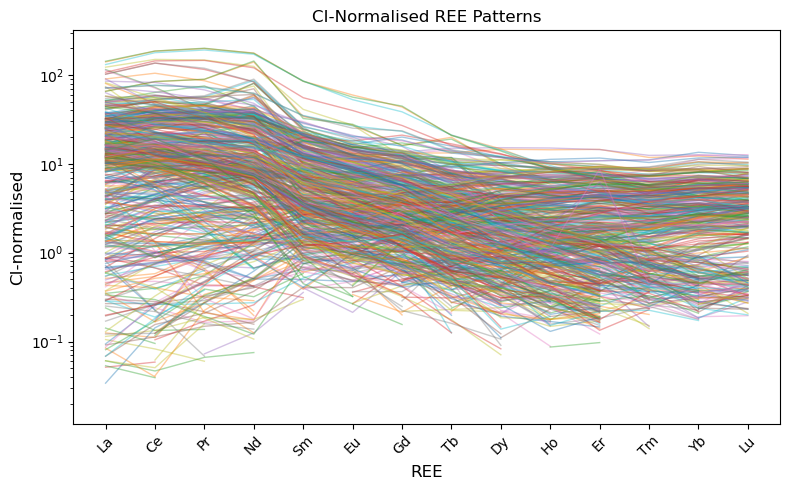

In [88]:
# CI values (same order as REE columns)
CI = np.array([
    0.2472, 0.6308, 0.0950, 0.4793, 0.1542, 0.0592,
    0.2059, 0.0375, 0.2540, 0.0554, 0.1645, 0.0258,
    0.1684, 0.0251
])
plt.figure(figsize=(8,5))

for _, row in df_cpx_ree.iterrows():
    values = row[ree_columns].values.astype(float)
    norm = values / CI
    plt.plot(ree_columns, norm, alpha=0.4)

plt.yscale("log")
plt.xlabel("REE")
plt.ylabel("CI-normalised")
plt.title("CI-Normalised REE Patterns")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [89]:
# plt.figure(figsize=(8,5))

# for _, row in df_cpx_ree.iterrows():
#     values = row[ree_columns].values.astype(float)
#     norm = values / CI
#     ln_norm = np.log(norm)
#     plt.plot(ree_columns, ln_norm, alpha=0.4)

# plt.xlabel("REE")
# plt.ylabel("ln(REE/CI)")
# plt.title("ln(CI-normalised REE)")
# plt.xticks(rotation=45)
# plt.tight_layout()
# plt.show()

In [79]:
lambda_results = []

for _, row in df_cpx_ree.iterrows():
    sample = row[ree_columns].values.astype(float)
    out = lambda_lnREE(sample, degree=4, exclude=(), sigma_frac=0.01)
    lambda_results.append(out["lambdas"])

lambda_array = np.vstack(lambda_results)

# Put into dataframe
lambda_df = pd.DataFrame(lambda_array, columns=["λ0","λ1","λ2","λ3","λ4"])

print(lambda_df.head(-1))

           λ0         λ1          λ2           λ3           λ4
0    1.706819  24.540636 -146.699919 -1036.599851 -1477.126952
1    1.713648  24.465402 -142.671096 -1122.987912 -1818.697288
2    1.758205  23.145501 -154.678605  -955.623702  4507.222824
3    1.817215  35.527246  -69.060561 -2331.086472 -2839.556580
4         NaN        NaN         NaN          NaN          NaN
..        ...        ...         ...          ...          ...
574  0.955497  29.487740   29.014234 -1439.043099 -3703.902796
575       NaN        NaN         NaN          NaN          NaN
576       NaN        NaN         NaN          NaN          NaN
577       NaN        NaN         NaN          NaN          NaN
578       NaN        NaN         NaN          NaN          NaN

[579 rows x 5 columns]


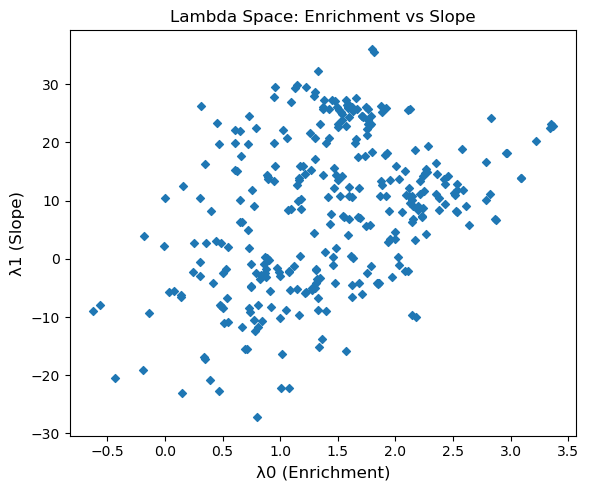

In [80]:
plt.figure(figsize=(6,5))
plt.scatter(lambda_df["λ0"], lambda_df["λ1"])
plt.xlabel("λ0 (Enrichment)")
plt.ylabel("λ1 (Slope)")
plt.title("Lambda Space: Enrichment vs Slope")
plt.tight_layout()
plt.show()

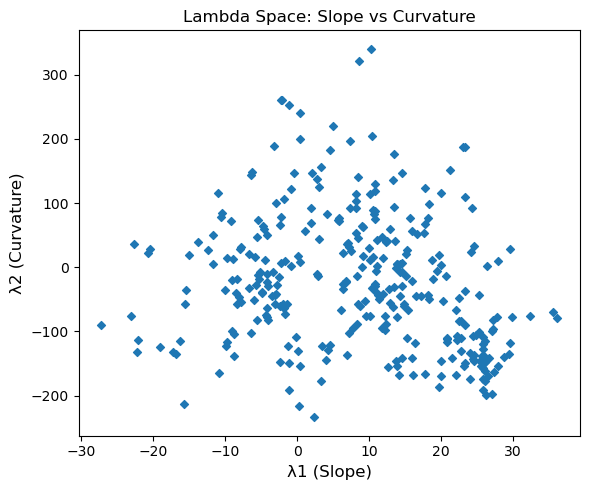

In [81]:
plt.figure(figsize=(6,5))
plt.scatter(lambda_df["λ1"], lambda_df["λ2"])
plt.xlabel("λ1 (Slope)")
plt.ylabel("λ2 (Curvature)")
plt.title("Lambda Space: Slope vs Curvature")
plt.tight_layout()
plt.show()

In [90]:
import pyrolite.plot
lp = df_cpx_ree.pyrochem.lambda_lnREE(algorithm="ONeill")
lp.head()

,λ0,λ1,λ2,λ3
420,1.769184,24.673525,-148.024023,-1037.700701
421,1.774329,24.593283,-143.769396,-1123.021537
422,1.820527,23.281659,-155.552097,-955.443478
423,1.874455,35.616948,-73.348403,-2338.048957
424,1.338894,33.590238,-107.808073,-1536.642461


In [91]:
import numpy as np
import pandas as pd

# --- your manual lambdas ---
lambda_results = []
for _, row in df_cpx_ree.iterrows():
    sample = row[ree_columns].values.astype(float)
    out = lambda_lnREE(sample, degree=4, exclude=(), sigma_frac=0.01)
    lambda_results.append(out["lambdas"])

lambda_df = pd.DataFrame(np.vstack(lambda_results), columns=["λ0","λ1","λ2","λ3","λ4"])
lambda_df["SAMPLE NO."] = df_cpx_ree["SAMPLE NO."].values
lambda_df = lambda_df.set_index("SAMPLE NO.").sort_index()

# --- pyrolite/pyrochem lambdas ---
lp = df_cpx_ree.pyrochem.lambda_lnREE(algorithm="ONeill").copy()

# attach sample numbers (pyrochem returns same row order as df_cpx_ree)
lp["SAMPLE NO."] = df_cpx_ree["SAMPLE NO."].values
lp = lp.set_index("SAMPLE NO.").sort_index()

# rename lp columns to match λ0..λ4 if needed
rename_map = {
    "lambda0":"λ0","lambda1":"λ1","lambda2":"λ2","lambda3":"λ3","lambda4":"λ4",
    "Λ0":"λ0","Λ1":"λ1","Λ2":"λ2","Λ3":"λ3","Λ4":"λ4",
}
lp = lp.rename(columns={k:v for k,v in rename_map.items() if k in lp.columns})

# compare only shared lambda columns (important if lp has no λ4)
cols = [c for c in ["λ0","λ1","λ2","λ3","λ4"] if c in lambda_df.columns and c in lp.columns]

A, B = lambda_df[cols].align(lp[cols], join="inner", axis=0)

diff = A - B

print("allclose:", np.allclose(A.to_numpy(), B.to_numpy(), rtol=1e-6, atol=1e-8, equal_nan=True))
print("\nMax abs diff per column:\n", diff.abs().max())
print("\nMedian abs diff per column:\n", diff.abs().median())

# show worst offenders
worst = diff.abs().max(axis=1).sort_values(ascending=False).head(10).index
display(pd.concat({"manual": A.loc[worst], "pyrochem": B.loc[worst], "diff": diff.loc[worst]}, axis=1))

allclose: False

Max abs diff per column:
 λ0     0.101882
λ1     0.310706
λ2    14.671644
λ3    50.955649
dtype: float64

Median abs diff per column:
 λ0    0.027003
λ1    0.075857
λ2    2.999048
λ3    8.335466
dtype: float64


manual                                      pyrochem  \
                      λ0         λ1          λ2           λ3        λ0   
SAMPLE NO.                                                               
MT. T C2R3 C    0.158408  12.444806   40.991512 -1038.216987  0.124629   
MT. S C5R2 C    0.525624  -1.818138  107.090390  1716.926071  0.460541   
MT.AA10 C4R2 C  0.882638  14.487347  147.398269 -2312.247372  0.830454   
MT. T C6R3 C    0.550601   2.082734  147.436131  -588.287066  0.485044   
MT. S C8R4 R    1.456963   0.312548  199.606076   875.365595  1.429309   
MT. W C5R3 C   -0.187473 -19.138668 -123.831523 -2238.371892 -0.137304   
MT. S C6R3 C    1.346121  -3.250542  188.839860  1414.254288  1.315223   
MT. W C5R2 R    1.295008   4.473032  182.377755  -178.783408  1.275252   
MT. T C5R2 C    1.077533  -2.141420  261.228261  2511.916055  0.975651   
MT. T C6R2 R    1.075699  -2.278379  260.624674  2565.058744  0.973855   

                                                        diff            \
                       λ1          λ2           λ3        λ0        λ1   
SAMPLE NO.                                                               
MT. T C2R3 C    12.310026   54.785768  -987.261338  0.033779  0.134779   
MT. S C5R2 C    -2.015201  121.762034  1761.659085  0.065083  0.197062   
MT.AA10 C4R2 C  14.290330  157.533343 -2269.616309  0.052184  0.197016   
MT. T C6R3 C     1.874596  159.015733  -546.463537  0.065557  0.208138   
MT. S C8R4 R     0.225613  188.697327   834.840965  0.027654  0.086935   
MT. W C5R3 C   -18.935300 -137.383279 -2277.542102 -0.050168 -0.203368   
MT. S C6R3 C    -3.338731  179.321858  1376.710394  0.030898  0.088189   
MT. W C5R2 R     4.400346  171.491544  -215.691472  0.019756  0.072686   
MT. T C5R2 C    -2.452126  273.789534  2546.712498  0.101882  0.310706   
MT. T C6R2 R    -2.588668  273.191397  2599.696115  0.101844  0.310290   

                                      
                       λ2         λ3  
SAMPLE NO.                            
MT. T C2R3 C   -13.794256 -50.955649  
MT. S C5R2 C   -14.671644 -44.733014  
MT.AA10 C4R2 C -10.135074 -42.631063  
MT. T C6R3 C   -11.579602 -41.823529  
MT. S C8R4 R    10.908749  40.524629  
MT. W C5R3 C    13.551756  39.170210  
MT. S C6R3 C     9.518002  37.543895  
MT. W C5R2 R    10.886210  36.908064  
MT. T C5R2 C   -12.561273 -34.796443  
MT. T C6R2 R   -12.566723 -34.637371

In [94]:
# --- % differences ---
eps = 1e-12  # prevent blow-ups when B is ~0

pct_signed = (diff / (B.replace(0, np.nan))) * 100
pct_abs = (diff.abs() / (B.abs() + eps)) * 100

print("\nMedian signed % diff per column:\n", pct_signed.median(numeric_only=True))
print("\nMedian absolute % diff per column:\n", pct_abs.median(numeric_only=True))

print("\nMax absolute % diff per column:\n", pct_abs.max(numeric_only=True))

# mean absolute percentage error (MAPE-style)
mape = pct_abs.mean()
print("\nMean absolute % diff (MAPE) per column:\n", mape)


Median signed % diff per column:
 λ0   -1.188100
λ1   -0.160932
λ2   -1.802996
λ3   -0.264299
dtype: float64

Median absolute % diff per column:
 λ0    1.952857
λ1    0.602455
λ2    4.034452
λ3    0.918078
dtype: float64

Max absolute % diff per column:
 λ0     207.033858
λ1     286.012995
λ2    2681.840951
λ3      91.328775
dtype: float64

Mean absolute % diff (MAPE) per column:
 λ0     4.696588
λ1     3.108007
λ2    22.776646
λ3     2.824924
dtype: float64


In [98]:
import numpy as np

def _safe_ln_ratio(x, ci):
    """ln(x/ci) with NaN for invalid (<=0 or non-finite)."""
    x = np.asarray(x, float)
    ci = np.asarray(ci, float)
    y = np.full_like(x, np.nan, dtype=float)
    good = np.isfinite(x) & np.isfinite(ci) & (x > 0) & (ci > 0)
    y[good] = np.log(x[good] / ci[good])
    return y, good

def _ols_cov_se(F, y, beta):
    """
    Classic OLS covariance and standard errors.
    Returns (cov, se, dof, s2, resid)
    """
    n, p = F.shape
    resid = y - F @ beta
    dof = n - p
    if dof <= 0:
        return None, None, dof, np.nan, resid
    sse = float(np.sum(resid**2))
    s2 = sse / dof
    XtX_inv = np.linalg.inv(F.T @ F)
    cov = s2 * XtX_inv
    se = np.sqrt(np.diag(cov))
    return cov, se, dof, s2, resid

def _wls_cov_se(F, y, sigma_ln, beta):
    """
    WLS covariance and standard errors when sigma_ln is provided.
    Returns (cov, se, dof, resid, chisq)
    """
    n, p = F.shape
    resid = y - F @ beta
    dof = n - p
    w = 1.0 / (sigma_ln**2)
    W = np.diag(w)
    FTWF = F.T @ W @ F
    cov = np.linalg.inv(FTWF)
    se = np.sqrt(np.diag(cov))
    chisq = float(np.sum((resid / sigma_ln) ** 2))
    return cov, se, dof, resid, chisq

def lambda_lnREE(
    sample_ppm,
    degree=4,
    exclude=(),
    sigma_frac=None,
    s_lnREE_percent=2.0,   # BLambdaR "uncert" equivalent (% uncertainty in ln-space)
    ree_order=REE,
    radii=IONIC_RADII,
    ci=CI,
):
    """
    Returns BLambdaR-style outputs:
      - lambdas, cov, se, se_percent
      - y_obs (ln-space), y_pred_used (ln-space)
      - SSE, dof, red_chi_sq, R2, adj_R2
      - predicted pattern + MFR for all 14 REE
    """
    sample_ppm = np.asarray(sample_ppm, dtype=float)
    radii = np.asarray(radii, dtype=float)
    ci = np.asarray(ci, dtype=float)

    # Base mask from exclusions (Ce/Eu/Gd etc.)
    mask_excl = get_mask(exclude=exclude, ree_order=ree_order)

    # ln(REE/CI) and validity
    y_all, good_all = _safe_ln_ratio(sample_ppm, ci)

    # Fit only where: not excluded AND good (finite and >0)
    fit_mask = mask_excl & good_all

    rr = radii[fit_mask]
    y = y_all[fit_mask]

    # Build sigma_ln vector if provided, otherwise None.
    sigma_ln = None
    if sigma_frac is not None:
        sigma_frac = np.asarray(sigma_frac, dtype=float)
        if sigma_frac.size == 1:
            sigma_ln_all = np.full_like(sample_ppm, float(sigma_frac))
        else:
            # expects length 14 aligned to REE
            sigma_ln_all = sigma_frac
        sigma_ln = sigma_ln_all[fit_mask]

    # Design matrix on used radii
    F = oneill_2016_basis(rr, degree=degree)

    n, p = F.shape
    if n < p:
        raise ValueError(f"Not enough valid REEs to fit degree={degree}: need >= {p}, have {n}.")

    # Fit
    lambdas, _ = fit_lambdas(F, y, sigma_ln=sigma_ln)

    # Predictions (used points)
    y_pred_used = F @ lambdas
    resid_used = y - y_pred_used
    sse = float(np.sum(resid_used**2))
    dof = int(n - p)

    # R2 / adj R2 in ln-space (OLS-style definition)
    y_mean = float(np.mean(y))
    tss = float(np.sum((y - y_mean) ** 2))
    R2 = np.nan if tss == 0 else 1.0 - (sse / tss)
    adj_R2 = np.nan
    if dof > 0 and tss != 0:
        adj_R2 = 1.0 - (1.0 - R2) * (n - 1) / dof

    # Reduced chi-squared (BLambdaR-style):
    # BLambdaR uses user-provided s(ln[REE]) in percent.
    # If sigma_frac provided (WLS), we can compute chisq from sigma_ln as well.
    if sigma_ln is None:
        sigma_ln_assumed = 0.01 * float(s_lnREE_percent)
        chisq = float(np.sum((resid_used / sigma_ln_assumed) ** 2))
        red_chi_sq = np.nan if dof <= 0 else chisq / dof
        cov, se, dof2, s2, _ = _ols_cov_se(F, y, lambdas)
    else:
        cov, se, dof2, _, chisq = _wls_cov_se(F, y, sigma_ln, lambdas)
        red_chi_sq = np.nan if dof <= 0 else chisq / dof

    # SE% like BLambdaR (se/abs(coef)*100)
    se_percent = None
    if se is not None:
        with np.errstate(divide="ignore", invalid="ignore"):
            se_percent = (se / np.abs(lambdas)) * 100.0

    # Predict full 14-REE fitted curve in ln-space and REE/CI space
    F_all = oneill_2016_basis(radii, degree=degree)
    y_pred_all = F_all @ lambdas                 # ln(REE/CI) predicted for all 14
    pred_ratio_all = np.exp(y_pred_all)          # (REE/CI) predicted for all 14

    # Observed ratio and MFR (measured / fitted), all 14
    obs_ratio_all = np.full_like(sample_ppm, np.nan, dtype=float)
    ok = good_all
    obs_ratio_all[ok] = sample_ppm[ok] / ci[ok]

    MFR_all = np.full_like(sample_ppm, np.nan, dtype=float)
    MFR_all[ok] = obs_ratio_all[ok] / pred_ratio_all[ok]

    return {
        # core
        "lambdas": lambdas,
        "cov": cov,
        "se": se,
        "se_percent": se_percent,

        # fit masks / data
        "exclude": exclude,
        "fit_mask": fit_mask,          # points actually used in regression
        "valid_mask": good_all,        # finite and >0
        "degree": degree,

        # ln-space
        "y_obs_used": y,
        "y_pred_used": y_pred_used,
        "resid_used": resid_used,

        # stats
        "n_used": int(n),
        "n_params": int(p),
        "dof": dof,
        "SSE": sse,
        "chi_sq": chisq,
        "red_chi_sq": red_chi_sq,
        "R2": R2,
        "adj_R2": adj_R2,

        # full-pattern predictions
        "y_pred_all": y_pred_all,          # ln(REE/CI) for all 14
        "pred_ratio_all": pred_ratio_all,  # predicted (REE/CI) for all 14
        "obs_ratio_all": obs_ratio_all,    # observed (REE/CI) for all 14
        "MFR_all": MFR_all,                # measured/fitted ratio for all 14
    }

out = lambda_lnREE(PM, degree=4, exclude=("Eu",), s_lnREE_percent=2.0)

print("λ0..λ4:", out["lambdas"])
print("dof:", out["dof"])
print("adj R²:", out["adj_R2"])
print("reduced χ²:", out["red_chi_sq"])
print("SE%:", out["se_percent"])

# MFR per element
for el, mfr in zip(REE, out["MFR_all"]):
    print(f"{el}_MFR: {mfr:.3f}" if np.isfinite(mfr) else f"{el}_MFR: NA")

λ0..λ4: [ 1.03952694e+00 -1.62402644e-01 -1.89499927e+00  2.40908701e+01
 -2.73008170e+02]
dof: 8
adj R²: 0.9082019571421378
reduced χ²: 0.03675334723927569
SE%: [ 0.10229892 10.86478046 19.94774662 31.51558875 59.52317746]
La_MFR: 1.000
Ce_MFR: 0.999
Pr_MFR: 1.002
Nd_MFR: 0.999
Sm_MFR: 0.999
Eu_MFR: 0.993
Gd_MFR: 1.000
Tb_MFR: 1.004
Dy_MFR: 0.995
Ho_MFR: 1.006
Er_MFR: 0.994
Tm_MFR: 1.003
Yb_MFR: 0.999
Lu_MFR: 1.001
